<h1>Employee Attrition Prediction</h1>

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,accuracy_score,classification_report,confusion_matrix,roc_auc_score


<h3>Data Loading & Exploration</h3
>

In [ ]:
# Load the CSV file using Pandas

df=pd.read_csv("../Dataset/Employeedataset.csv")

In [9]:
# Display the first 10 rows

df.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [10]:
# Check how many rows and columns are there

df.shape

(1470, 35)

In [11]:
# Identify the target column (Attrition — Yes/No)

df["Attrition"].head(10)

0    Yes
1     No
2    Yes
3     No
4     No
5     No
6     No
7     No
8     No
9     No
Name: Attrition, dtype: object

In [12]:
# Count how many employees left vs stayed and calculate the attrition rate as a percentage

x,y=df["Attrition"].value_counts()
totalEmployee=df["Attrition"].count()
print("Percentage of No :",(x/totalEmployee)*100)
print("\nPercentage of Yes :",(y/totalEmployee)*100)

Percentage of No : 83.87755102040816

Percentage of Yes : 16.122448979591837


In [13]:
# Identify how many columns are numeric vs categorical
CategoricalColumn=[x for x in df.columns if df.dtypes[x]=="object"]
NumericalColumn=[x for x in df.columns if df.dtypes[x]!="object"]
print("Categorical Cloumns :\n",CategoricalColumn)
print("\nNumerical Cloumns :\n",NumericalColumn)

Categorical Cloumns :
 ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numerical Cloumns :
 ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


* <h2>The attrition rate is imbalanced becaude the number of no count is more than the number of Yes cound</h2>

* <h3>Attritation Percentage of No : 83.87755102040816</h3>

* <h3>Attritation Percentage of Yes : 16.122448979591837</h3>

<h1>Data Cleaning & Preprocessing</h1>

In [14]:
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

**No column contain null elements**

In [15]:
# Convert the target column Attrition from Yes/No to 1/0

df["Attrition"]=df["Attrition"].map({"Yes":1,"No":0})

In [16]:
# using statistical test to find relation between columns with "Attrition" column

# t-test
# Binary output column vs numeric columns
significant=[]
nonsignificant=[]
for col in NumericalColumn:
    group1=df[df["Attrition"]==0][col]
    group2=df[df["Attrition"]==1][col]
    stat,pValue=ttest_ind(group1,group2)
    if pValue<0.05:
        significant.append(col)
    else:
        nonsignificant.append(col)
print("Significant columns :", significant)
print("\n Non Significant columns :",nonsignificant)




Significant columns : ['Age', 'DailyRate', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager']

 Non Significant columns : ['Education', 'EmployeeCount', 'EmployeeNumber', 'HourlyRate', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'YearsSinceLastPromotion']


c:\Users\Abhishek k\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


In [17]:
CategoricalColumn.remove("Attrition")

In [18]:
# Annova test

for col in CategoricalColumn:
    table=pd.crosstab(df["Attrition"],df[col])
    chi2, pValue, dof, expected=chi2_contingency(table)
    if pValue<0.05:
        significant.append(col)
    else:
        nonsignificant.append(col)
print("Significant columns :", significant)
print("\n Non Significant columns :",nonsignificant)
       


Significant columns : ['Age', 'DailyRate', 'DistanceFromHome', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager', 'BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus', 'OverTime']

 Non Significant columns : ['Education', 'EmployeeCount', 'EmployeeNumber', 'HourlyRate', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'YearsSinceLastPromotion', 'Gender', 'Over18']


In [19]:
# # Drop columns that add no value to prediction
print("Shape before droping non significant numeric columns",df.shape)
df=df.drop(columns=nonsignificant,axis=1)
print("\nShape after droping non significant numeric columns",df.shape)


Shape before droping non significant numeric columns (1470, 35)

Shape after droping non significant numeric columns (1470, 22)


In [20]:
# Separate target and features column

y=df["Attrition"]
x=df.drop(columns=["Attrition"],axis=1)


In [21]:
# Encode all remaining categorical columns using One-Hot Encoding 
CategoricalColumn=[x for x in x.columns if df.dtypes[x]=="object"]
encoder=OneHotEncoder(sparse_output=False)
encoded_data=encoder.fit_transform(x[CategoricalColumn])
encoded_df=pd.DataFrame(encoded_data,columns=encoder.get_feature_names_out(CategoricalColumn))
x = x.reset_index(drop=True)
encoded_df = encoded_df.reset_index(drop=True)

x = pd.concat(
    [
        x.drop(columns=CategoricalColumn),
        encoded_df
    ],
    axis=1
)

In [22]:
# Scale numeric features using StandardScaler
scaler=StandardScaler()
x=pd.DataFrame(scaler.fit_transform(x),columns=x.columns)
x

,Age,DailyRate,DistanceFromHome,EnvironmentSatisfaction,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,StockOptionLevel,TotalWorkingYears,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,OverTime_No,OverTime_Yes
0,0.446350,0.742527,-1.010909,-0.660531,0.379672,-0.057788,1.153254,-0.108350,-0.932014,-0.421642,...,-0.330808,-0.239904,-0.497873,1.873287,-0.244625,-0.534873,-0.918921,1.458650,-1.591746,1.591746
1,1.322365,-1.297775,-0.147150,0.254625,-1.026167,-0.057788,-0.660853,-0.291719,0.241988,-0.164511,...,-0.330808,-0.239904,2.008543,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,0.628241,-0.628241
2,0.008343,1.414363,-0.887515,1.169781,-1.026167,-0.961486,0.246200,-0.937654,-0.932014,-0.550208,...,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,-0.534873,-0.918921,1.458650,-1.591746,1.591746
3,-0.429664,1.461466,-0.764121,1.169781,0.379672,-0.961486,0.246200,-0.763634,-0.932014,-0.421642,...,-0.330808,-0.239904,2.008543,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,-1.591746,1.591746
4,-1.086676,-0.524295,-0.887515,-1.575686,0.379672,-0.961486,-0.660853,-0.644858,0.241988,-0.678774,...,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,0.628241,-0.628241
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,-0.101159,0.202082,1.703764,0.254625,1.785511,-0.057788,1.153254,-0.835451,0.241988,0.735447,...,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,0.628241,-0.628241
1466,0.227347,-0.469754,-0.393938,1.169781,-1.026167,0.845911,-1.567907,0.741140,0.241988,-0.293077,...,-0.330808,-0.239904,-0.497873,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,0.628241,-0.628241
1467,-1.086676,-1.605183,-0.640727,-0.660531,1.785511,-0.057788,-0.660853,-0.076690,0.241988,-0.678774,...,3.022901,-0.239904,-0.497873,-0.533821,-0.244625,-0.534873,1.088232,-0.685565,-1.591746,1.591746
1468,1.322365,0.546677,-0.887515,1.169781,-1.026167,-0.057788,-0.660853,-0.236474,-0.932014,0.735447,...,-0.330808,-0.239904,-0.497873,1.873287,-0.244625,-0.534873,1.088232,-0.685565,0.628241,-0.628241


In [23]:
# Attrition rate by Department — which department loses the most employees?
attrition_rate=df.groupby("Department")["Attrition"].mean()*100
print(attrition_rate)
print("\n",attrition_rate.idxmax(),"Deparment looses highest percentage(",attrition_rate.max(),")employees")

Department
Human Resources           19.047619
Research & Development    13.839750
Sales                     20.627803
Name: Attrition, dtype: float64

 Sales Deparment looses highest percentage( 20.62780269058296 )employees


*   Sales departmet looses most employees

In [24]:
# Attrition rate by Job Role — which roles have the highest exit rate?

attrition_rate=df.groupby("JobRole")["Attrition"].mean()*100
print(attrition_rate)
print("\n",attrition_rate.idxmax(),"jobrole employees exits at highest percentage of",attrition_rate.max())


JobRole
Healthcare Representative     6.870229
Human Resources              23.076923
Laboratory Technician        23.938224
Manager                       4.901961
Manufacturing Director        6.896552
Research Director             2.500000
Research Scientist           16.095890
Sales Executive              17.484663
Sales Representative         39.759036
Name: Attrition, dtype: float64

 Sales Representative jobrole employees exits at highest percentage of 39.75903614457831


*  Sales Representative jobrole have the highest exit rate

In [25]:
# Attrition vs Monthly Income — do lower paid employees leave more?

attrition_rate=df.groupby("MonthlyIncome")["Attrition"].mean()*100
print(attrition_rate)
print("\n Monthly Income",attrition_rate.idxmax(),"  Leave rate",attrition_rate.max())

MonthlyIncome
1009     100.0
1051       0.0
1052       0.0
1081     100.0
1091     100.0
         ...  
19859    100.0
19926      0.0
19943      0.0
19973      0.0
19999      0.0
Name: Attrition, Length: 1349, dtype: float64

 Monthly Income 1009   Leave rate 100.0


* Yes, employees with lowest monthly income leaves more

In [26]:
import os

# create folder if not exists
os.makedirs("charts", exist_ok=True)

In [27]:
# Attrition vs Work-Life Balance rating — is there a visible pattern?

attrition_rate=df.groupby("WorkLifeBalance")["Attrition"].mean()*100
print(attrition_rate)
plt.Figure(figsize=(10,8))
sns.barplot(
    x=attrition_rate.index,
    y=attrition_rate.values
)
plt.xlabel("Work Life Balance")
plt.ylabel("Attrition rate")
plt.savefig("charts/Attrition_vs_WorklifeBalance.png",dpi=300,bbox_inches="tight")
plt.show()

WorkLifeBalance
1    31.250000
2    16.860465
3    14.221725
4    17.647059
Name: Attrition, dtype: float64


AttributeError: module 'matplotlib' has no attribute 'backends'

Error in callback <function _enable_matplotlib_integration.<locals>.configure_once at 0x000001F92E0B40E0> (for post_run_cell), with arguments args (<ExecutionResult object at 1f92da8baa0, execution_count=27 error_before_exec=None error_in_exec=module 'matplotlib' has no attribute 'backends' info=<ExecutionInfo object at 1f92da8be60, raw_cell="# Attrition vs Work-Life Balance rating — is there.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell:/c%3A/Users/Abhishek%20k/codes%20learning/projects/weather%20website/Attrition/EmployeeAttrition_Abhishek_K/analysis.ipynb#X36sZmlsZQ%3D%3D> result=None>,),kwargs {}:


AttributeError: module 'matplotlib' has no attribute 'backends'

* WorkLifeBalance **1** have highest attrition rate 
* Attrition rate is decreasing while increasing Worklife balance not in a steady manner

In [ ]:
#  Attrition vs Years at Company — at what point in tenure do employees leave most?
attrition_rate=df.groupby("YearsAtCompany")["Attrition"].agg(Number_of_employees="count",Number_of_employees_left="sum",Attition_rate="mean")
print(attrition_rate)
attrition_rate.sort_index(ascending=True)


                Number_of_employees  Number_of_employees_left  Attition_rate
YearsAtCompany                                                              
0                                44                        16       0.363636
1                               171                        59       0.345029
2                               127                        27       0.212598
3                               128                        20       0.156250
4                               110                        19       0.172727
5                               196                        21       0.107143
6                                76                         9       0.118421
7                                90                        11       0.122222
8                                80                         9       0.112500
9                                82                         8       0.097561
10                              120                        18       0.150000

,Number_of_employees,Number_of_employees_left,Attition_rate
YearsAtCompany,,,
0,44,16,0.363636
1,171,59,0.345029
2,127,27,0.212598
3,128,20,0.156250
4,110,19,0.172727
5,196,21,0.107143
6,76,9,0.118421
7,90,11,0.122222
8,80,9,0.112500


 * Employees with **0** experiencce leave most

<h1>EDA Analysis</h1>

* Sales Deparment looses highest percentage( 20.62780269058296 )employees
* Sales Representative jobrole employees exits at highest percentage of 39.75903614457831
* Yes, employees with lowest monthly income leaves more
* Employees with **0** experiencce leave most
* WorkLifeBalance **1** have highest attrition rate
* Attrition rate is decreasing while increasing Worklife balance not in a steady manner

In [ ]:
# plit data into training and test sets (80/20)
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

<h1> Model Building & Comparison</h1>

In [ ]:
# Handle class imbalance using class_weight='balanced' parameter (a simpler approach than SMOTE — good to know both exist)
# Train the following 3 models : 1. Logistic Regression 2.Random Forest Classifier 3. Gradient Boosting Classifier

models={
    "Logistic Regression":LogisticRegression(class_weight='balanced'),
    "Random Forest Classifier":RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced'),
    "Gradient Boosting Classifier":GradientBoostingClassifier(n_estimators=100,random_state=42)

}

In [ ]:
# Record all results in a comparison table inside your notebook
result=[]
for name,model in models.items():
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    mae=mean_squared_error(y_test,y_pred)
    mse=mean_squared_error(y_test,y_pred)
    r2score=r2_score(y_test,y_pred)
    accuracy=accuracy_score(y_test,y_pred)
    result.append([name,mae,mse,r2score,accuracy])
resultdf=pd.DataFrame(result,columns=["Model","Mean absolute error","Mean squared error","R2 Score","Accuracy"])
resultdf

,Model,Mean absolute error,Mean squared error,R2 Score,Accuracy
0,Logistic Regression,0.275510,0.275510,-1.394570,0.724490
1,Random Forest Classifier,0.139456,0.139456,-0.212066,0.860544
2,Gradient Boosting Classifier,0.122449,0.122449,-0.064253,0.877551


In [ ]:
for name,model in models.items():
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    print("\n\n",name,"Classification Report\n\n",classification_report(y_test,y_pred))
    print(name,"roc auc score :",roc_auc_score(y_test,y_pred))
    print("\n\n",name,"Condusion matrix\n",confusion_matrix(y_test,y_pred))





 Logistic Regression Classification Report

               precision    recall  f1-score   support

           0       0.92      0.75      0.82       255
           1       0.26      0.59      0.36        39

    accuracy                           0.72       294
   macro avg       0.59      0.67      0.59       294
weighted avg       0.83      0.72      0.76       294

Logistic Regression roc auc score : 0.667420814479638


 Logistic Regression Condusion matrix
 [[190  65]
 [ 16  23]]


 Random Forest Classifier Classification Report

               precision    recall  f1-score   support

           0       0.87      0.98      0.92       255
           1       0.38      0.08      0.13        39

    accuracy                           0.86       294
   macro avg       0.62      0.53      0.53       294
weighted avg       0.81      0.86      0.82       294

Random Forest Classifier roc auc score : 0.5286576168929109


 Random Forest Classifier Condusion matrix
 [[250   5]
 [ 36   3]]


In [ ]:
# Identify and clearly state which model performed best 
# by mean absolute error
# Low mean absolute error=best model
resultdf.sort_values(by="Mean absolute error",ascending=True)

,Model,Mean absolute error,Mean squared error,R2 Score,Accuracy
2,Gradient Boosting Classifier,0.122449,0.122449,-0.064253,0.877551
1,Random Forest Classifier,0.139456,0.139456,-0.212066,0.860544
0,Logistic Regression,0.275510,0.275510,-1.394570,0.724490


In [ ]:
# by mean squared error
# Low mean squared error=best model
resultdf.sort_values(by="Mean squared error",ascending=True)

,Model,Mean absolute error,Mean squared error,R2 Score,Accuracy
2,Gradient Boosting Classifier,0.122449,0.122449,-0.064253,0.877551
1,Random Forest Classifier,0.139456,0.139456,-0.212066,0.860544
0,Logistic Regression,0.275510,0.275510,-1.394570,0.724490


In [ ]:
#by r2 score
# High r2 score=best model
resultdf.sort_values(by="R2 Score",ascending=False)

,Model,Mean absolute error,Mean squared error,R2 Score,Accuracy
2,Gradient Boosting Classifier,0.122449,0.122449,-0.064253,0.877551
1,Random Forest Classifier,0.139456,0.139456,-0.212066,0.860544
0,Logistic Regression,0.275510,0.275510,-1.394570,0.724490


In [ ]:
#by accuracy score
# High accuracy score=best model
resultdf.sort_values(by="Accuracy",ascending=False)

,Model,Mean absolute error,Mean squared error,R2 Score,Accuracy
2,Gradient Boosting Classifier,0.122449,0.122449,-0.064253,0.877551
1,Random Forest Classifier,0.139456,0.139456,-0.212066,0.860544
0,Logistic Regression,0.275510,0.275510,-1.394570,0.724490


<h1>Best Model : Gradient Boosting Classifier</h1>

* Highest accuracy score
* Least mse and mae score
* Highest r2 sccore
* Highest accuracy 

In [ ]:
model=GradientBoostingClassifier(n_estimators=100,random_state=42)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print("\n\n",name,"\n\nClassification Report\n\n",classification_report(y_test,y_pred))
print(name,"roc auc score :",roc_auc_score(y_test,y_pred))
print("\n\n",name,"Condusion matrix\n",confusion_matrix(y_test,y_pred))





 Gradient Boosting Classifier 

Classification Report

               precision    recall  f1-score   support

           0       0.90      0.96      0.93       255
           1       0.57      0.31      0.40        39

    accuracy                           0.88       294
   macro avg       0.74      0.64      0.67       294
weighted avg       0.86      0.88      0.86       294

Gradient Boosting Classifier roc auc score : 0.6361990950226244


 Gradient Boosting Classifier Condusion matrix
 [[246   9]
 [ 27  12]]


In [ ]:
# For the best model: extract Feature Importance
features=pd.DataFrame({"Features":x_train.columns,
                       "Importance":(model.feature_importances_)*100
})
features.head()

,Features,Importance
0,Age,6.468721
1,DailyRate,5.831303
2,DistanceFromHome,4.998401
3,EnvironmentSatisfaction,2.768042
4,JobInvolvement,4.992210


In [ ]:
# Rank the top 10 most important features driving employee exit
top10=features.sort_values(by="Importance",ascending=False).head(10)
top10

,Features,Importance
7,MonthlyIncome,14.548806
39,OverTime_No,8.409941
0,Age,6.468721
1,DailyRate,5.831303
5,JobLevel,5.505430
40,OverTime_Yes,5.132233
12,YearsAtCompany,5.087719
2,DistanceFromHome,4.998401
4,JobInvolvement,4.992210
8,StockOptionLevel,4.590301


<h1> Visualization </h1>

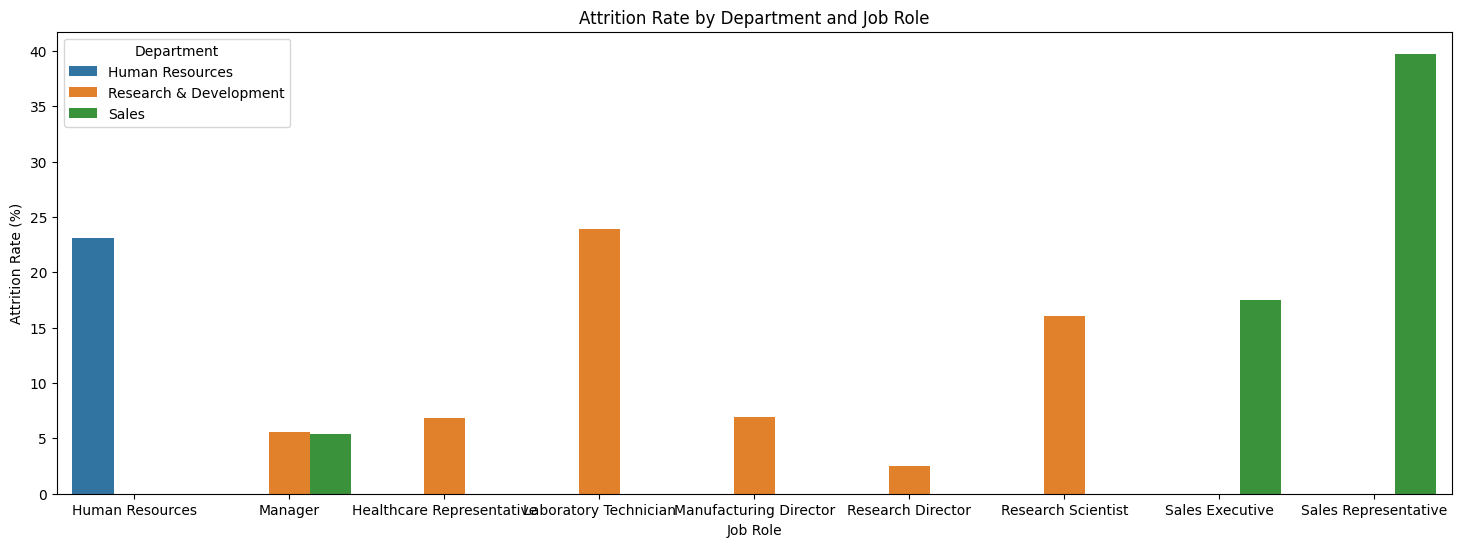

In [ ]:
# Chart 1: Bar chart showing attrition rate by Department and Job Role
x=df.groupby(["Department","JobRole"])["Attrition"].mean().mul(100).reset_index()
plt.figure(figsize=(18,6))
sns.barplot(data=x,
            x="JobRole",y="Attrition",hue="Department")
plt.title("Attrition Rate by Department and Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Job Role")
plt.show()

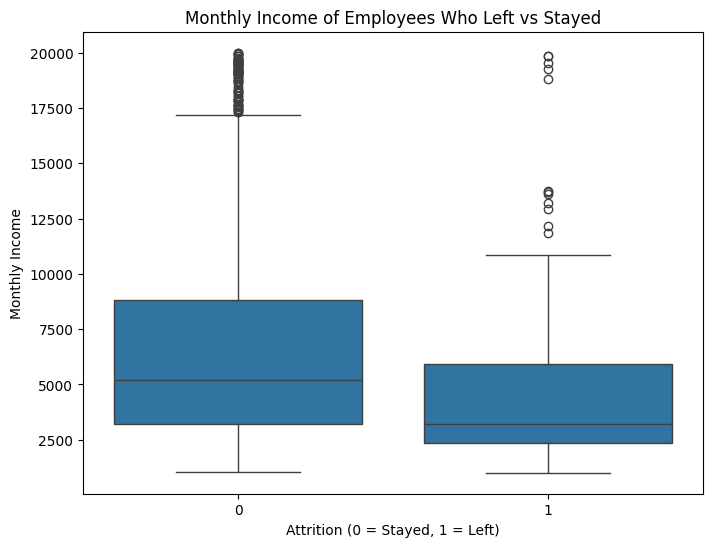

In [ ]:
# Chart 2: Box plot comparing Monthly Income of employees who left vs stayed
plt.figure(figsize=(8,6))
sns.boxplot(x="Attrition",y="MonthlyIncome",data=df)
plt.title("Monthly Income of Employees Who Left vs Stayed")
plt.xlabel("Attrition (0 = Stayed, 1 = Left)")
plt.ylabel("Monthly Income")
plt.show()


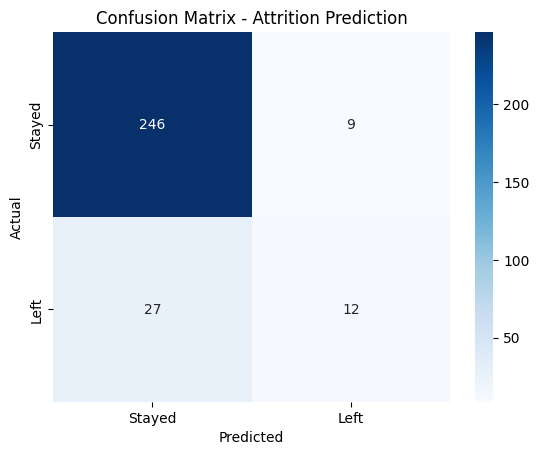

In [ ]:
# Chart 3: Confusion Matrix heatmap for your best model
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt="d",
    cmap="Blues", xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Attrition Prediction")
plt.show()

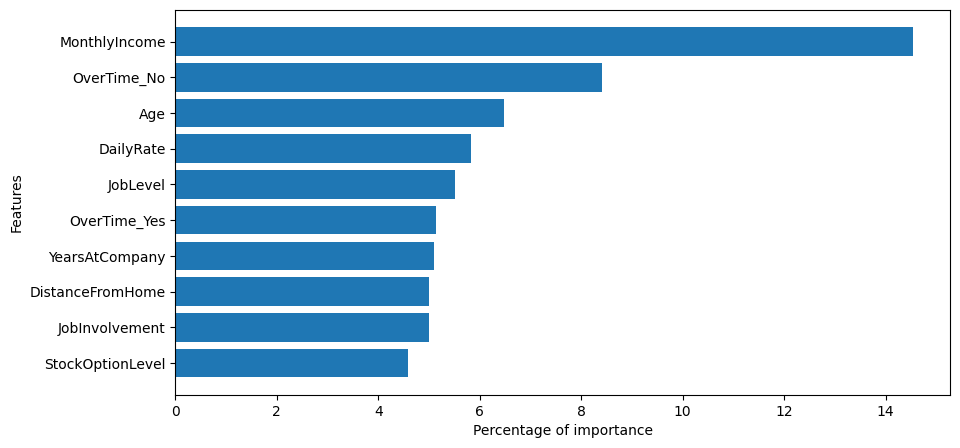

In [ ]:
# Chart 4: Horizontal bar chart of Top 10 Feature Importances from your best model
plt.figure(figsize=(10,5))
plt.barh(top10["Features"],top10["Importance"])
plt.xlabel("Percentage of importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()


<h1>HR Insights & Business Recommendations</h1>

1. Which 3 factors most strongly predict that an employee will leave?
* * MonthlyIncome
  * OverTime_No
  * Age
<br>
2. Which department or job role should HR prioritize for retention efforts?
* Department
  * Sales
* Job Role
  * Sales Representative 
<br>
3. Does salary alone explain attrition or are there other stronger factors?
* Monthly Income is related to the attrition rate but it alone can't explain attrition.
<br>
4. Write 2 concrete HR recommendations a company could implement based on your
findings 
* Focus on freshers,attrition rate of employees with **0** experience is higher
* Monthly income is one of the main feature affect attrition rate,focusing on hiking salary for best employees and offer best salary for good new employees
<br>
5. What limitation does this model have that an HR team should be aware of before
using it?
* Model says an employee has 80% attrition risk,
It does not mean they will definitely leave.
* The model learns from past employee data.

  * If past data has:

    * old company policies
    * old salary structures
    * past work culture
* the model may not perform well on future employees.